=== Этап 1: Загрузка и исследование данных ===
Размерность датасета: (1500, 9)

Информация о пропусках в данных:
patient_id                0
age                      45
gender                    0
drug_class                0
dosage_mg                 0
polypharmacy_count        0
history_of_allergies      0
blood_pressure_status    30
severe_adr                0
dtype: int64


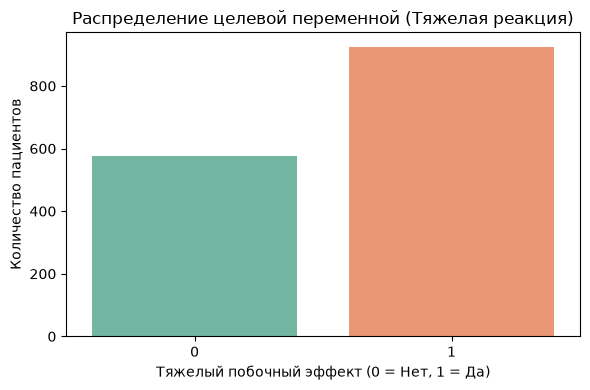

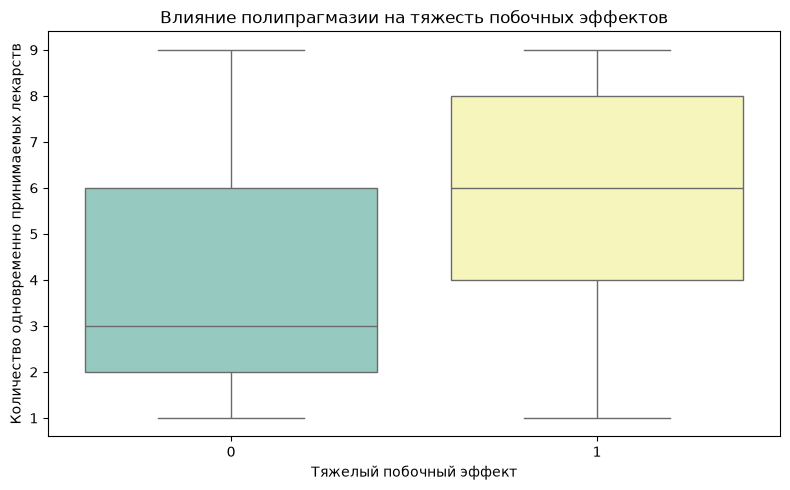


Размер обучающей выборки: 1200, тестовой: 300

=== Этап 3: Ообучение моделей ===
Обучение Logistic Regression...
Запуск кросс-валидации для Random Forest...
Запуск кросс-валидации для XGBoost...

=== Этап 4: Сводная оценка моделей ===

Метрики для Logistic Regression:
  Accuracy: 0.7100
  Precision: 0.7188
  Recall: 0.8703
  F1-Score: 0.7873
  ROC-AUC: 0.7561

Метрики для Random Forest (Optimized):
  Accuracy: 0.6733
  Precision: 0.6820
  Recall: 0.8811
  F1-Score: 0.7689
  ROC-AUC: 0.7468

Метрики для XGBoost (Optimized):
  Accuracy: 0.6967
  Precision: 0.6926
  Recall: 0.9135
  F1-Score: 0.7879
  ROC-AUC: 0.7328


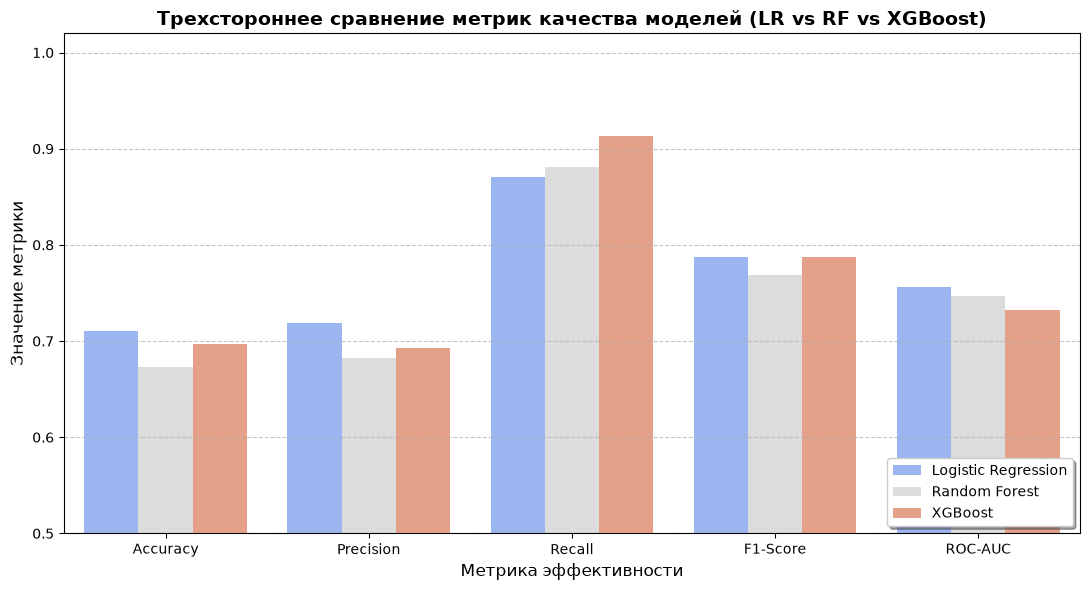

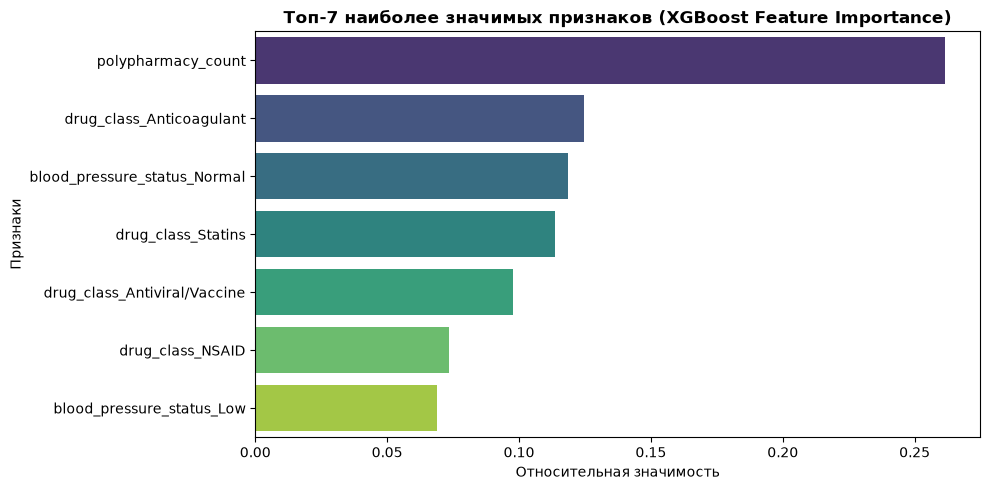


Построение матрицы ошибок для лучшей модели (XGBoost)...


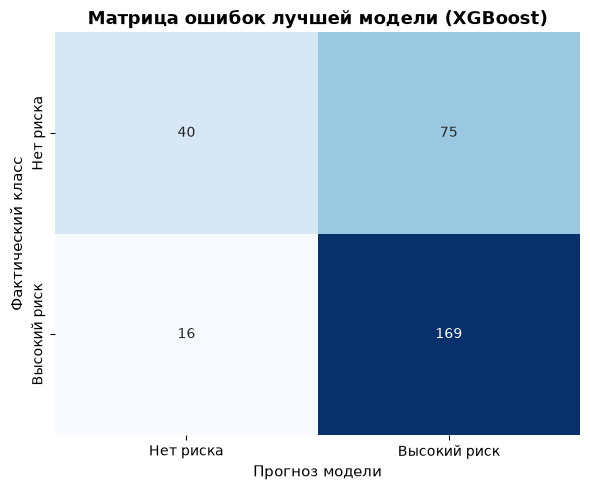


Все графики успешно построены и сохранены!


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

# === ЭТАП 1: ЗАГРУЗКА И ИССЛЕДОВАНИЕ ДАННЫХ (EDA) ===
print("=== Этап 1: Загрузка и исследование данных ===")
current_dir = os.path.dirname(os.path.abspath('__file__'))
path_to_file = os.path.join(current_dir, 'adverse_drug_reactions.csv')

# Проверка наличия файла (для локального запуска)
if not os.path.exists(path_to_file):
    raise FileNotFoundError(f"Файл {path_to_file} не найден. Пожалуйста, поместите его в рабочую директорию.")

df = pd.read_csv(path_to_file)
print(f"Размерность датасета: {df.shape}")
print("\nИнформация о пропусках в данных:")
print(df.isnull().sum())

# Визуализация 1: Распределение целевой переменной
plt.figure(figsize=(6, 4))
sns.countplot(x='severe_adr', data=df, palette='Set2', hue='severe_adr', legend=False)
plt.title('Распределение целевой переменной (Тяжелая реакция)')
plt.xlabel('Тяжелый побочный эффект (0 = Нет, 1 = Да)')
plt.ylabel('Количество пациентов')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150)
plt.show()

# Визуализация 2: Влияние полипрагмазии
plt.figure(figsize=(8, 5))
sns.boxplot(x='severe_adr', y='polypharmacy_count', data=df, palette='Set3', hue='severe_adr', legend=False)
plt.title('Влияние полипрагмазии на тяжесть побочных эффектов')
plt.xlabel('Тяжелый побочный эффект')
plt.ylabel('Количество одновременно принимаемых лекарств')
plt.tight_layout()
plt.savefig('polypharmacy_impact.png', dpi=150)
plt.show()

# === ЭТАП 2: РАЗДЕЛЕНИЕ ДАННЫХ И ПРЕДОБРАБОТКА ===
X = df.drop(columns=['patient_id', 'severe_adr'])
y = df['severe_adr']

numeric_features = ['age', 'dosage_mg', 'polypharmacy_count']
categorical_features = ['gender', 'drug_class', 'blood_pressure_status']

# Разделение на train/test с сохранением пропорций классов (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nРазмер обучающей выборки: {X_train.shape[0]}, тестовой: {X_test.shape[0]}")

# Пайплайны трансформации данных
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())                  
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), 
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore')) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# === ЭТАП 3: ОБУЧЕНИЕ МОДЕЛЕЙ И ПОДБОР ПАРАМЕТРОВ ===
print("\n=== Этап 3: Ообучение моделей ===")

# Модель 1: Логистическая регрессия (Baseline)
print("Обучение Logistic Regression...")
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])
log_reg_pipeline.fit(X_train, y_train)

# Модель 2: Случайный лес (Random Forest) + GridSearchCV
print("Запуск кросс-валидации для Random Forest...")
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])
param_grid_rf = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5]
}
grid_search_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=5, scoring='f1', n_jobs=-1)
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_

# Модель 3: Градиентный бустинг (XGBoost) + GridSearchCV
print("Запуск кросс-валидации для XGBoost...")
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss'))
])
param_grid_xgb = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2]
}
grid_search_xgb = GridSearchCV(xgb_pipeline, param_grid_xgb, cv=5, scoring='f1', n_jobs=-1)
grid_search_xgb.fit(X_train, y_train)
best_xgb_model = grid_search_xgb.best_estimator_

# === ЭТАП 4: ОЦЕНКА И СРАВНЕНИЕ МОДЕЛЕЙ ===
print("\n=== Этап 4: Сводная оценка моделей ===")

def evaluate_model(model, X_ts, y_ts, model_name):
    y_pred = model.predict(X_ts)
    y_prob = model.predict_proba(X_ts)[:, 1]
    
    metrics = {
        'Accuracy': accuracy_score(y_ts, y_pred),
        'Precision': precision_score(y_ts, y_pred),
        'Recall': recall_score(y_ts, y_pred),
        'F1-Score': f1_score(y_ts, y_pred),
        'ROC-AUC': roc_auc_score(y_ts, y_prob)
    }
    print(f"\nМетрики для {model_name}:")
    for k, v in metrics.items():
        print(f"  {k}: {v:.4f}")
    return metrics

lr_metrics = evaluate_model(log_reg_pipeline, X_test, y_test, "Logistic Regression")
rf_metrics = evaluate_model(best_rf_model, X_test, y_test, "Random Forest (Optimized)")
xgb_metrics = evaluate_model(best_xgb_model, X_test, y_test, "XGBoost (Optimized)")

# Формирование таблицы для построения сводного графика
metrics_list = []
for name, m_dict in zip(['Logistic Regression', 'Random Forest', 'XGBoost'], [lr_metrics, rf_metrics, xgb_metrics]):
    for metric_name, value in m_dict.items():
        metrics_list.append({'Model': name, 'Metric': metric_name, 'Value': value})
df_metrics_plot = pd.DataFrame(metrics_list)

# График сравнение всех трех моделей
plt.figure(figsize=(11, 6))
sns.barplot(x='Metric', y='Value', hue='Model', data=df_metrics_plot, palette='coolwarm')
plt.title('Трехстороннее сравнение метрик качества моделей (LR vs RF vs XGBoost)', fontsize=14, fontweight='bold')
plt.ylim(0.5, 1.02)
plt.ylabel('Значение метрики', fontsize=12)
plt.xlabel('Метрика эффективности', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right', shadow=True, fontsize=10)
plt.tight_layout()
plt.savefig('models_comparison.png', dpi=150)
plt.show()

# Визуализация важности признаков для лучшей модели (XGBoost)
classifier_step = best_xgb_model.named_steps['classifier']
encoder_step = best_xgb_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
cat_features_transformed = encoder_step.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + cat_features_transformed
importances = classifier_step.feature_importances_

feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(7), hue='Feature', legend=False, palette='viridis')
plt.title('Топ-7 наиболее значимых признаков (XGBoost Feature Importance)', fontsize=12, fontweight='bold')
plt.xlabel('Относительная значимость')
plt.ylabel('Признаки')
plt.tight_layout()
plt.savefig('feature_importance_xgb.png', dpi=150)
plt.show()

# === ЭТАП 4.3: АНАЛИЗ ОШИБОК ПОБЕДИТЕЛЯ (XGBoost Confusion Matrix) ===
print("\nПостроение матрицы ошибок для лучшей модели (XGBoost)...")

# Получаем прогнозы из уже оптимизированной модели, которая находится внутри GridSearchCV
y_pred_xgb_best = best_xgb_model.predict(X_test)

# Строим матрицу ошибок
cm_xgb = confusion_matrix(y_test, y_pred_xgb_best)

# Настройка и визуализация графика
labels = ['Нет риска', 'Высокий риск']
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb, 
    annot=True,           # Выводить числа внутри квадратов
    fmt='d',              # Формат чисел (целые)
    cmap='Blues',         # Красивая синяя палитра
    cbar=False,           # Отключаем боковую цветовую шкалу для аккуратности
    xticklabels=labels,   # Подписи для оси X (Прогноз)
    yticklabels=labels    # Подписи для оси Y (Факт)
)

plt.title('Матрица ошибок лучшей модели (XGBoost)', fontsize=13, fontweight='bold')
plt.xlabel('Прогноз модели', fontsize=11)
plt.ylabel('Фактический класс', fontsize=11)
plt.tight_layout()

# Сохраняем картинку для вашей презентации PowerPoint
plt.savefig('confusion_matrix_xgb.png', dpi=150)
plt.show()

print("\nВсе графики успешно построены и сохранены!")
